# 18장 스트림·합성 시나리오의 Jev

17장까지 Jev는 풀 기반 루프 안에서만 일했다. 이 장은 6장(스트림)과 7장(합성)의 비교 틀을 그대로 두고 Jev를 넣는다.

- 스트림: 도착한 문장마다 질의 여부를 바로 정해야 한다. 학생 모델의 엔트로피로 Jev에 넘길 문장을 먼저 거르고(사전 필터), Jev 판정으로 질의를 정한다. 호출 지연과 예산이 새 제약이 된다.
- 합성: Jev는 문장을 생성하지 못한다. 7장의 규칙 변형과 MLM 변형으로 후보 문장을 만들고, Jev가 라벨과 자연스러움을 판정해 고르고 라벨까지 붙인다(판정 기반 합성).

- 18.1 스트림 시나리오의 Jev 질의 판단
- 18.2 응답 지연과 호출 예산
- 18.3 Jev 판정 기반 합성 질의
- 18.4 합성 질의의 라벨 일관성
- 18.5 시나리오별 비교

학생 모델은 TF-IDF·로지스틱 회귀이고 CPU로 돈다. 초기 라벨 100개는 사람이 붙인다. Jev 판정은 4부의 슬림 형식과 13장 설정을 쓴다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


3장의 엔트로피 점수를 다시 싣는다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

Jev 호출 함수, 라벨 체계, 요청 형식은 14장과 같다. 합성 판정에 쓸 자연스러움 질문(noul)을 요청 형식에 더한다.

In [3]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64, 120, 240, 480, 600):   # 일시 오류·연결 끊김은 쉬었다 다시 보낸다(최대 약 26분)
        try:
            r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                             json=body, timeout=300)
        except requests.ConnectionError:                    # 오래 도는 실험에서 연결이 끊기면 잠시 쉬고 다시 보낸다
            time.sleep(wait)
            continue
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [4]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [5]:
# ── 라벨 스키마와 요청 만들기 (13장 + 지시문 변형·자기 평가 질문) ────
CHUNK = 50                               # 요청 하나에 넣는 문장 수
TASK_SENT = {"nsmc": "영화 리뷰의 감성을 분류한다.", "ynat": "뉴스 기사 제목의 주제를 분류한다."}
RULES = {"nsmc": ["반어나 비꼼으로 칭찬하는 척하는 리뷰는 부정이다",
                  "칭찬과 불만이 섞이면 글쓴이의 최종 평가를 따른다",
                  "영화 밖의 이야기(배우, 다른 관객)라도 영화에 대한 태도가 드러나면 그 태도를 따른다"],
         "ynat": ["기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다",
                  "사건·사고·교육·노동·법원·지역 소식은 사회다",
                  "국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다",
                  "문화·연예·건강·여행·종교·생활 정보는 생활문화다",
                  "경기 결과·선수·구단·대회는 스포츠다"]}
# 지시문 변형 v1: 같은 뜻을 다른 말로 쓴 과제 문장과 라벨 설명
TASK_ALT = {"nsmc": "리뷰를 쓴 사람이 영화를 좋게 봤는지 나쁘게 봤는지 가린다.",
            "ynat": "기사 제목을 보고 어느 지면에 실릴 기사인지 가린다."}
LABEL_DESC_ALT = {"nsmc": {"부정": "영화가 별로였다는 리뷰", "긍정": "영화가 좋았다는 리뷰"},
                  "ynat": {"IT과학": "컴퓨터·인터넷·통신·과학 소식", "경제": "기업·시장·돈의 흐름에 관한 소식",
                           "사회": "사건·사고와 사회 문제", "생활문화": "생활 정보·문화·건강·여행",
                           "세계": "다른 나라 소식", "스포츠": "경기와 선수 소식", "정치": "정부·국회·정당·외교·북한 소식"}}
SURE_LEVELS = ["어느 라벨인지 알 수 없다", "두 라벨 사이에서 헷갈린다", "한 라벨에 기울지만 다른 라벨일 수 있다",
               "거의 분명하다", "의심할 여지 없이 분명하다"]

def schema_text(name, level, desc, task, names):
    lines = [f"과제: {task[name]}", "라벨:"]
    lines += [f"- {n}: {desc[name][n]}" if level >= 1 else f"- {n}" for n in names]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level == 2 else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, shots=(), desc=LABEL_DESC, task=TASK_SENT, reverse=False, sure=False):
    # reverse: 라벨 목록과 선택지 순서를 뒤집는다. sure: 문장마다 자기 평가 질문 sure_i를 더한다
    names = LABEL_NAMES[name][::-1] if reverse else LABEL_NAMES[name]
    one = lambda t: str(t).replace("\n", " ")
    parts = [schema_text(name, schema, desc, task, names)]
    parts += ["예시:\n" + "\n".join(f'- "{one(t)}" → {y}' for t, y in shots)] if len(shots) else []
    state = "\n\n".join(parts + ["분류할 문장:\n" + "\n".join(f"[{i}] {one(t)}" for i, t in enumerate(texts))])
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 문장의 라벨", "criteria": {n: None for n in names}}
          for i in range(len(texts))}
    qs.update({f"sure_{i}": {"type": "score", "instructions": f"[{i}]번 문장의 라벨은 얼마나 분명한가?", "criteria": SURE_LEVELS}
               for i in range(len(texts))} if sure else {})
    return state, qs

In [6]:
# ── 설정 ────
BEST = {"nsmc": dict(schema=1, n=8), "ynat": dict(schema=2, n=7)}     # 13장 Jev 오라클 설정
UNIT = {"nsmc": 50, "ynat": 80}                                       # 00_기획안 4.2절 가정: 사람 라벨 단가(원)
REVIEW, R_REVIEW = 0.6, 20                                            # 혼합 오라클: 신뢰도 하위 20% 검수, 단가의 60%
SCHUNK = 200                                                          # 스트림 덩어리(재학습 간격, 6장)
RATE = (BUDGET - N_INIT) / (20000 - N_INIT)                           # 예산을 정확히 다 쓰는 평균 질의율(6장)
PF = 0.3                                                              # 사전 필터 통과율 목표

def pick_bal(d, idx0, n, rng):
    y0 = d["y_pool"][idx0]
    # 드리프트 스트림의 초기 100개에는 없는 클래스가 있다. 있는 만큼만 고른다
    pick = np.concatenate([rng.choice(idx0[y0 == c], min(n // d["n_classes"], (y0 == c).sum()), replace=False) for c in range(d["n_classes"])])
    return rng.permutation(pick)

def oracle_cfg(d, idx0, seed):
    # 13장 Jev 오라클과 같은 방식: 그 실행의 초기 라벨 100개에서 클래스 균형 예시를 고른다
    pick = pick_bal(d, idx0, BEST[d["name"]]["n"], np.random.default_rng(seed))
    return dict(schema=BEST[d["name"]]["schema"], shots=[(d["texts"][i], LABEL_NAMES[d["name"]][d["y_pool"][i]]) for i in pick])

def norm_entropy(P):
    return score_entropy(P) / np.log(P.shape[1])

def kl_div(PJ, P):
    return (PJ * (np.log(PJ + 1e-12) - np.log(P + 1e-12))).sum(1)

In [7]:
# ── Jev 판정: 라벨과 자연스러움 ────
_build_request = build_request

def build_request(name, texts, nat=False, **cfg):
    # nat=True면 문장마다 「자연스러운 문장인가」 noul 질문 nat_i를 더한다(18.3절)
    state, qs = _build_request(name, texts, **cfg)
    qs.update({f"nat_{i}": {"type": "noul", "instructions": f"[{i}]번 문장은 사람이 쓴 것처럼 자연스러운 한국어 문장인가?"}
               for i in range(len(texts))} if nat else {})
    return state, qs

def jev_label(name, texts, cfg, nat=False, chunk=CHUNK, conc=MAX_CONC):
    # texts를 chunk개씩 묶어 판정한다. (선택지 확률 행렬, 자연스러움 확률, 묶음별 사용량)
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + chunk], nat=nat, **cfg)
        n = len(texts[s:s + chunk])
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        P = [[ans[f"label_{i}"]["probabilities"].get(m, 0.0) for m in names] for i in range(n)]
        q = [ans[f"nat_{i}"]["noul"] if nat else np.nan for i in range(n)]
        return P, q, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=n)
    with ThreadPoolExecutor(conc) as ex:
        out = list(ex.map(one, range(0, len(texts), chunk)))
    P = np.array([p for o in out for p in o[0]])
    return P / P.sum(1, keepdims=True), np.array([q for o in out for q in o[1]]), pd.DataFrame([o[2] for o in out])

In [8]:
# ── Jev 판정 저장소 ────
import os
os.makedirs("results/ch18_parts", exist_ok=True)

def load_cache(tag):
    # 열쇠는 풀 인덱스(스트림) 또는 문장(합성)이다. 값은 (확률, 자연스러움 확률, 토큰 몫)
    path = f"results/ch18_parts/jev_{tag}.csv"
    if not os.path.exists(path):
        return {}
    df = pd.read_csv(path, keep_default_na=False, na_values=[""])
    P = df.filter(regex=r"^p\d").values.astype(float)
    keys = df.key.astype(str).values
    return {k: (p, q, t) for k, p, q, t in zip(keys, P, df.nat.values.astype(float), df.n_in.values)}

def save_cache(tag, cache):
    rows = [dict(key=k, nat=q, n_in=t, **{f"p{j}": x for j, x in enumerate(p)}) for k, (p, q, t) in cache.items()]
    pd.DataFrame(rows).to_csv(f"results/ch18_parts/jev_{tag}.csv", index=False)

def jev_lookup(name, keys, texts, cache, cfg, nat=False):
    # 저장소에 없는 것만 Jev에 묻는다. (확률 행렬, 자연스러움 확률, 토큰 몫 합, 이번에 새로 쓴 토큰)
    keys = [str(k) for k in keys]
    seen, miss = set(), []
    for j, k in enumerate(keys):
        if k not in cache and k not in seen:
            seen.add(k)
            miss.append(j)
    new = 0.0
    if miss:
        P, q, u = jev_label(name, np.asarray(texts, dtype=object)[miss], cfg, nat=nat)
        per = np.repeat(u.n_in.values / u.n.values, u.n.values)
        cache.update({keys[j]: (p, a, t) for j, p, a, t in zip(miss, P, q, per)})
        new = u.n_in.sum()
    rows = [cache[k] for k in keys]
    return np.array([r[0] for r in rows]), np.array([r[1] for r in rows]), sum(r[2] for r in rows), new

## 18.1 스트림 시나리오의 Jev 질의 판단

6장의 스트림을 그대로 쓴다. 시드마다 풀 20,000개를 섞은 도착 순서, 초기 100개, 예산 2,000개, 재학습 간격 200개다. 오라클 함수는 (라벨, 신뢰도)를 돌려주고 루프는 라벨만 학습에 쓴다.

Jev를 넣는 방법은 둘이다.

| 칸 | 질의 | 라벨 |
|---|---|---|
| VU·Jev | 6장 VU(정규화 엔트로피, 가변 문턱, 예산 조건) | Jev 오라클 |
| Jev 불일치 스트림 | 사전 필터를 지난 문장만 Jev가 판정하고 KL(p_Jev ‖ p_θ)가 가변 문턱 θ를 넘으면 질의 | 판정 재사용 |
| Jev 불일치 스트림·혼합 | 위와 같음 | 판정 재사용 + 덩어리마다 질의 라벨의 신뢰도 하위 20% 검수 |

사전 필터가 없으면 도착 19,900개를 모두 판정해야 한다. 필터는 정규화 엔트로피가 θ_f를 넘는 문장만 Jev에 넘긴다. θ_f는 넘기면 (1 + s(1 − 0.3))배, 안 넘기면 (1 − s·0.3)배로 움직여 통과율이 30%에 머문다. 질의 문턱 θ와 예산 조건은 VU와 같다. 예산을 다 쓰면 Jev를 더 부르지 않는다.

Jev 판정은 시드마다 저장소에 두고 칸끼리 함께 쓴다. 스트림의 초기 라벨은 풀 기반 루프와 달라 퓨샷 예시가 다르므로 4부 판정은 물려받지 않는다. 학습 방식은 모든 칸에서 기본(하드 라벨)이다.

In [9]:
# ── 스트림 루프 ────
def run_stream(make_fns, data, seed, order=None, n_init=N_INIT, budget=BUDGET, chunk=SCHUNK):
    # 6장 run_stream과 같다. make_fns(초기 인덱스)가 (질의 함수, 오라클 함수, 상태)를 만든다.
    # 오라클 함수는 (라벨, 신뢰도)를 돌려준다. 상태에는 토큰·검수 수를 쌓는다
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    order = rng.permutation(n) if order is None else order
    idx_l = order[:n_init]
    y_l = data["y_pool"][idx_l]                                                    # 초기 100개는 사람 라벨
    query_fn, oracle_fn, st = make_fns(idx_l)
    log, preq, n_fit = [], [], -1
    for start in list(range(n_init, len(order), chunk)) + [len(order)]:
        if len(idx_l) != n_fit:
            model, n_fit = train_model(data["X_pool"][idx_l], y_l, seed), len(idx_l)          # 1. train
            y_hat = model.predict(data["X_test"])
        log.append(dict(seed=seed, n_seen=start, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"),
                        noise=(y_l != data["y_pool"][idx_l]).mean(), **{k: st[k] for k in ("tok", "new", "judged", "reviews")}))
        if start == len(order):
            break
        arrive = order[start:start + chunk]
        preq.append(model.predict(data["X_pool"][arrive]))
        q = query_fn(model, data, idx_l, y_l, arrive, budget - len(idx_l), rng)                # 2. predict · 3. query
        y_q, _ = oracle_fn(q, data["texts"][q])                                                 # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                           # 5. update
    return pd.DataFrame(log), idx_l, np.concatenate(preq)

def new_state():
    return dict(tok=0.0, new=0.0, judged=0, reviews=0)

def make_vu(theta=0.5, s=0.01, rate=RATE):
    # 6장 가변 불확실성(VU): 질의하면 θ를 올리고 아니면 내린다. 질의율이 rate를 넘으면 판단하지 않는다
    st = dict(theta=theta, seen=0, asked=0)
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        u = norm_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
        picked = []
        for i, ui in zip(idx_u, u):
            st["seen"] += 1
            if st["asked"] < st["seen"] * rate and len(picked) < k:
                ask = ui > st["theta"]
                st["theta"] *= (1 + s) if ask else (1 - s)
                st["asked"] += ask
                picked += [i] if ask else []
        return np.array(picked, dtype=int)
    return query_fn

def make_stream_random(rate=RATE):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        return idx_u[rng.random(len(idx_u)) < rate][:k]
    return query_fn

In [10]:
# ── Jev 불일치 스트림 ────
def make_jev_stream(name, cache, cfg, st, memo, rate=RATE, pf=PF, s=0.01):
    # 사전 필터: 정규화 엔트로피가 θ_f를 넘으면 Jev에 넘긴다. θ_f는 통과율이 pf가 되도록 움직인다
    # 질의: 넘긴 문장의 KL(p_Jev ‖ p_θ)가 θ를 넘으면 질의한다. θ와 예산 조건은 VU와 같다
    th = dict(f=0.5, kl=0.5, seen=0, asked=0)
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        if k <= 0:                                            # 예산을 다 쓰면 Jev를 부르지 않는다
            th["seen"] += len(idx_u)
            return np.array([], dtype=int)
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        go = np.zeros(len(idx_u), bool)
        for j, uj in enumerate(norm_entropy(P)):
            go[j] = uj > th["f"]
            th["f"] *= (1 + s * (1 - pf)) if go[j] else (1 - s * pf)
        pas = np.flatnonzero(go)
        kl, pj = {}, {}
        if len(pas):
            PJ, _, tok, new = jev_lookup(name, idx_u[pas], data["texts"][idx_u[pas]], cache, cfg)
            st["tok"], st["new"], st["judged"] = st["tok"] + tok, st["new"] + new, st["judged"] + len(pas)
            kl, pj = dict(zip(pas, kl_div(PJ, P[pas]))), dict(zip(pas, PJ))
        picked = []
        for j in range(len(idx_u)):
            th["seen"] += 1
            if j in kl and th["asked"] < th["seen"] * rate and len(picked) < k:
                ask = kl[j] > th["kl"]
                th["kl"] *= (1 + s) if ask else (1 - s)
                th["asked"] += ask
                picked += [j] if ask else []
        memo.clear()
        memo.update({int(idx_u[j]): pj[j] for j in picked})
        return idx_u[np.array(picked, dtype=int)]
    return query_fn

def make_oracles(d, cache, cfg, st, memo):
    # 스트림 오라클 셋. 모두 (라벨, 신뢰도)를 돌려준다
    y_true = d["y_pool"]
    def human(q, texts):
        return y_true[q], np.ones(len(q))
    def jev(q, texts):                                     # 질의와 따로 Jev 라벨을 받는다(VU·Jev)
        P, _, tok, new = jev_lookup(d["name"], q, texts, cache, cfg)
        st["tok"], st["new"] = st["tok"] + tok, st["new"] + new
        return (P.argmax(1), P.max(1)) if len(q) else (np.array([], int), np.array([]))
    def reuse(q, texts):                                   # 질의 판정 재사용(17장)
        P = np.array([memo[int(i)] for i in q]).reshape(len(q), d["n_classes"])
        return P.argmax(1), P.max(1)
    def mixed(q, texts):                                   # 재사용 + 이번 덩어리 질의의 신뢰도 하위 20% 검수
        y, c = reuse(q, texts)
        sel = np.argsort(c, kind="stable")[:round(len(q) * R_REVIEW / 100)]
        y[sel], st["reviews"] = y_true[q[sel]], st["reviews"] + len(sel)
        return y, c
    return dict(사람=human, Jev=jev, 재사용=reuse, 혼합=mixed)

def stream_arm(arm, d, seed, cache, rate=RATE):
    # 칸 이름 → make_fns(초기 인덱스)
    def make_fns(idx0):
        st, memo = new_state(), {}
        cfg = oracle_cfg(d, idx0, seed)
        orc = make_oracles(d, cache, cfg, st, memo)
        q = {"Random": lambda: make_stream_random(rate), "고정 τ=0.9": lambda: make_fixed(0.9),
             "VU": lambda: make_vu(rate=rate), "VU·Jev": lambda: make_vu(rate=rate),
             "Jev 불일치 스트림": lambda: make_jev_stream(d["name"], cache, cfg, st, memo, rate),
             "Jev 불일치 스트림·혼합": lambda: make_jev_stream(d["name"], cache, cfg, st, memo, rate)}[arm]()
        o = {"VU·Jev": "Jev", "Jev 불일치 스트림": "재사용", "Jev 불일치 스트림·혼합": "혼합"}.get(arm, "사람")
        return q, orc[o], st
    return make_fns

def make_fixed(tau):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        u = norm_entropy(proba(model, data["X_pool"][idx_u], data["n_classes"]))
        return idx_u[u > tau][:k]
    return query_fn

In [11]:
# ── 스트림 실험 도구(6장) ────
GRID = np.arange(N_INIT, BUDGET + 1, K)

def label_curve(d, metric="f1"):
    g = d.drop_duplicates("n_labeled", keep="last")
    return np.interp(GRID, g.n_labeled, g[metric])

def summarize_stream(res, metric="f1"):
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        per = []
        for _, d in g.groupby("seed"):
            done = d[d.n_labeled >= BUDGET].n_seen
            u = (d.n_seen - d.n_seen.iloc[0]) / (d.n_seen.iloc[-1] - d.n_seen.iloc[0])
            per.append(dict(ALC_label=alc(GRID, label_curve(d, metric)),
                            ALC_seen=np.sum(np.diff(u) * (d[metric].values[1:] + d[metric].values[:-1]) / 2),
                            final=d[metric].iloc[-1], labels=d.n_labeled.iloc[-1],
                            exhaust=done.iloc[0] if len(done) else np.nan,
                            label_acc=1 - d.noise.iloc[-1] * d.n_labeled.iloc[-1] / max(d.n_labeled.iloc[-1] - N_INIT, 1),
                            judged=d.judged.iloc[-1], tok=d.tok.iloc[-1], reviews=d.reviews.iloc[-1]))
        p = pd.DataFrame(per)
        rows.append(dict(strategy=name, ALC_label=p.ALC_label.mean(), ALC_label_std=p.ALC_label.std(ddof=0),
                         ALC_seen=p.ALC_seen.mean(), final=p.final.mean(), labels=p.labels.mean(), exhaust=p.exhaust.mean(),
                         label_acc=p.label_acc.mean(), judged=p.judged.mean(), tok=p.tok.mean(), reviews=p.reviews.mean()))
    return pd.DataFrame(rows).round(4)

In [12]:
# ── 정적 스트림 실험 ────
S_ARMS = ["Random", "VU", "VU·Jev", "Jev 불일치 스트림", "Jev 불일치 스트림·혼합"]

def run_stream_job(name, seed, arms, tag, order=None, rate=RATE):
    d, cache = DATA[name], load_cache(f"{tag}_{name}_{seed}")
    out = []
    for arm in arms:
        path = f"results/ch18_parts/{tag}_{name}_{arm.replace(' ', '_')}_{seed}.csv"
        if not os.path.exists(path):
            df, idx_l, pred = run_stream(stream_arm(arm, d, seed, cache, rate), d, seed, order=order)
            df.assign(data=name, strategy=arm).to_csv(path, index=False)
            np.save(path.replace(".csv", "_idx.npy"), idx_l)
            np.save(path.replace(".csv", "_preq.npy"), pred)
            save_cache(f"{tag}_{name}_{seed}", cache)
        out.append(pd.read_csv(path))
    return pd.concat(out, ignore_index=True)

t0 = time.perf_counter()
jobs = [(name, s) for name in DATA for s in SEEDS]
sres = pd.concat(Parallel(n_jobs=len(jobs))(delayed(run_stream_job)(n, s, S_ARMS, "stream") for n, s in jobs), ignore_index=True)
print(f"정적 스트림 완료 {(time.perf_counter() - t0) / 60:.1f}분")
for name in DATA:
    r = sres[sres.data == name]
    ch06 = pd.read_csv(f"results/ch06_{name}.csv")
    for s in ("Random", "VU"):
        print(name, s, "6장 대비 F1 최대 차이:", np.abs(ch06[ch06.strategy == s].f1.values - r[r.strategy == s].f1.values).max())
    print(f"\n{name} 스트림 (label_acc = 질의 라벨 정확도, judged = Jev 판정 문장 수, tok = 칸이 쓴 입력 토큰 몫)")
    print(summarize_stream(r).drop(columns=["ALC_label_std"]).to_string(index=False))

정적 스트림 완료 0.0분
nsmc Random 6장 대비 F1 최대 차이: 0.0
nsmc VU 6장 대비 F1 최대 차이: 0.0

nsmc 스트림 (label_acc = 질의 라벨 정확도, judged = Jev 판정 문장 수, tok = 칸이 쓴 입력 토큰 몫)
      strategy  ALC_label  ALC_seen  final  labels  exhaust  label_acc  judged         tok  reviews
        Random     0.7351    0.7349 0.7801  1992.6  19900.0     1.0000     0.0      0.0000      0.0
            VU     0.7416    0.7422 0.7841  2000.0  20000.0     1.0000     0.0      0.0000      0.0
        VU·Jev     0.7474    0.7479 0.7864  2000.0  20000.0     0.8781     0.0 195640.2000      0.0
   Jev 불일치 스트림     0.7691    0.7701 0.8037  1999.2  20000.0     0.9561  6053.4 551045.7556      0.0
Jev 불일치 스트림·혼합     0.7693    0.7703 0.8058  1999.4  20000.0     0.9753  6054.0 571972.8070    393.8
ynat Random 6장 대비 F1 최대 차이: 0.0
ynat VU 6장 대비 F1 최대 차이: 0.0

ynat 스트림 (label_acc = 질의 라벨 정확도, judged = Jev 판정 문장 수, tok = 칸이 쓴 입력 토큰 몫)
      strategy  ALC_label  ALC_seen  final  labels  exhaust  label_acc  judged         tok  reviews
        Rando

6장의 표류 스트림(YNAT, 길이 16,000, A 묶음 비율 0.9 → 0.1)에서 같은 비교를 한다. 6장 결론대로 고정 임계값은 표류 뒤쪽에서 질의가 끊긴다. Jev 판정은 학생의 학습 분포와 무관하므로 Jev 불일치 스트림이 표류 뒤쪽에서도 질의를 이어 가는지 본다. 지표는 6장과 같은 시험셋 F1, 1,000개 창의 사전 순차 F1, 구간별 질의 수다.

Random 6장 대비 F1 최대 차이: 0.0
고정 τ=0.9 6장 대비 F1 최대 차이: 0.0
VU 6장 대비 F1 최대 차이: 0.0


              final  labels  label_acc  judged          tok  사전순차_앞  사전순차_가운데  사전순차_뒤   질의_앞  질의_가운데   질의_뒤
strategy                                                                                                   
Random       0.6592  2000.0     1.0000     0.0       0.0000  0.2918    0.3255  0.5036  643.6   646.6  609.8
고정 τ=0.9     0.1252   100.0     1.0000     0.0       0.0000  0.2127    0.1616  0.0580    0.0     0.0    0.0
VU           0.6956  2000.0     1.0000     0.0       0.0000  0.3095    0.4021  0.5556  626.0   637.0  637.0
VU·Jev       0.6346  2000.0     0.7298     0.0  241730.2000  0.3044    0.5018  0.5981  626.0   637.0  637.0
Jev 불일치 스트림  0.6546  1998.6     0.7439  4840.4  571681.0098  0.3989    0.6491  0.6641  623.8   638.0  636.8


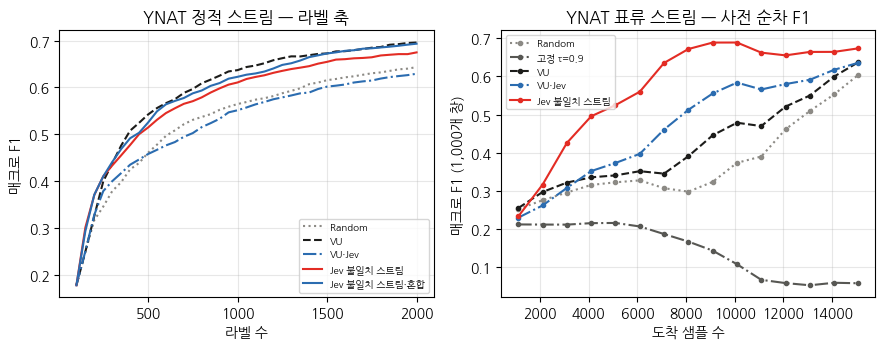

In [13]:
# ── 표류 스트림 ────
YNAT_NAMES = ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]
GROUP_A = [YNAT_NAMES.index(c) for c in ("정치", "경제", "사회")]
DRIFT_LEN = 16000
DRIFT_RATE = (BUDGET - N_INIT) / (DRIFT_LEN - N_INIT)

def make_drift_order(y, seed, n_each=DRIFT_LEN // 2):
    rng = np.random.default_rng(seed)
    a = list(rng.permutation(np.flatnonzero(np.isin(y, GROUP_A)))[:n_each])
    b = list(rng.permutation(np.flatnonzero(~np.isin(y, GROUP_A)))[:n_each])
    t = np.arange(2 * n_each) / (2 * n_each)
    p_a = np.clip(0.9 - 0.8 * (t - 1 / 3) * 3, 0.1, 0.9)
    order = []
    for p in p_a:
        src = a if (rng.random() < p and a) or not b else b
        order.append(src.pop())
    return np.array(order)

yn = DATA["ynat"]
orders = {s: make_drift_order(yn["y_pool"], s) for s in SEEDS}
D_ARMS = ["Random", "고정 τ=0.9", "VU", "VU·Jev", "Jev 불일치 스트림"]
dres = pd.concat(Parallel(n_jobs=len(SEEDS))(delayed(run_stream_job)("ynat", s, D_ARMS, "drift", orders[s], DRIFT_RATE)
                                             for s in SEEDS), ignore_index=True)
ch06 = pd.read_csv("results/ch06_drift.csv")
for s in ("Random", "고정 τ=0.9", "VU"):
    print(s, "6장 대비 F1 최대 차이:", np.abs(ch06[ch06.strategy == s].f1.values - dres[dres.strategy == s].f1.values).max())

W = 1000
rows, asked = [], []
for arm in D_ARMS:
    for s in SEEDS:
        base = f"results/ch18_parts/drift_ynat_{arm.replace(' ', '_')}_{s}"
        pred, idx_l = np.load(base + "_preq.npy"), np.load(base + "_idx.npy")
        truth = yn["y_pool"][orders[s][N_INIT:]]
        rows += [dict(strategy=arm, seed=s, pos=N_INIT + i + W, f1=f1_score(truth[i:i + W], pred[i:i + W], average="macro"))
                 for i in range(0, len(pred) - W + 1, W)]
        where = pd.Series(np.arange(len(orders[s])), index=orders[s]).loc[idx_l[N_INIT:]].values
        asked.append(dict(strategy=arm, 앞=(where < DRIFT_LEN / 3).sum(), 가운데=((where >= DRIFT_LEN / 3) & (where < 2 * DRIFT_LEN / 3)).sum(),
                          뒤=(where >= 2 * DRIFT_LEN / 3).sum()))
preq = pd.DataFrame(rows)
part = preq.assign(part=pd.cut(preq.pos, [0, DRIFT_LEN / 3, 2 * DRIFT_LEN / 3, DRIFT_LEN + 1], labels=["앞", "가운데", "뒤"]))
tabd = summarize_stream(dres).set_index("strategy")[["final", "labels", "label_acc", "judged", "tok"]].join(
    part.groupby(["strategy", "part"], observed=True).f1.mean().unstack().add_prefix("사전순차_")).join(
    pd.DataFrame(asked).groupby("strategy").mean().add_prefix("질의_"))
print(tabd.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
STY_S = dict(zip(["Random", "고정 τ=0.9", "VU", "VU·Jev", "Jev 불일치 스트림", "Jev 불일치 스트림·혼합"],
                 [(GRAY2, ":"), (GRAY, "-."), (INK, "--"), ("#2B6CB0", "-."), (ACCENT, "-"), ("#2B6CB0", "-")]))
for arm in S_ARMS:
    for ax, name in zip([axes[0]], ["ynat"]):
        g = sres[(sres.data == name) & (sres.strategy == arm)]
        lab = np.mean([label_curve(x) for _, x in g.groupby("seed")], axis=0)
        c, ls = STY_S[arm]
        ax.plot(GRID, lab, color=c, ls=ls, lw=1.5, label=arm)
axes[0].set(title="YNAT 정적 스트림 — 라벨 축", xlabel="라벨 수", ylabel="매크로 F1")
for arm in D_ARMS:
    m = preq[preq.strategy == arm].groupby("pos").f1.mean()
    c, ls = STY_S[arm]
    axes[1].plot(m.index, m.values, color=c, ls=ls, lw=1.5, marker="o", ms=3, label=arm)
axes[1].set(title="YNAT 표류 스트림 — 사전 순차 F1", xlabel="도착 샘플 수", ylabel="매크로 F1 (1,000개 창)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch18_stream.png", dpi=200)

질의한 문장을 질의 순서대로 3등분해 구간마다 B 묶음(정치·경제·사회가 아닌 클래스) 문장의 비율을 정답 기준과 학습에 들어간 라벨 기준으로 나눠 본다. VU는 사람 라벨이라 두 비율이 같다.

In [14]:
# ── 표류 구간별 B 묶음 비율: 고른 문장(정답)과 붙은 라벨 ────
rows = []
for arm in ["VU", "VU·Jev", "Jev 불일치 스트림"]:
    for s in SEEDS:
        base = f"results/ch18_parts/drift_ynat_{arm.replace(' ', '_')}_{s}"
        q = np.load(base + "_idx.npy")[N_INIT:]
        c = pd.read_csv(f"results/ch18_parts/jev_drift_ynat_{s}.csv")
        jl = pd.Series(c.filter(regex=r"^p\d").values.argmax(1), index=c.key.astype(int))
        for part, g in zip(["앞", "가운데", "뒤"], np.array_split(q, 3)):
            lab = yn["y_pool"][g] if arm == "VU" else jl.loc[g].values
            rows.append(dict(strategy=arm, part=part, 정답_B=(~np.isin(yn["y_pool"][g], GROUP_A)).mean(),
                             라벨_B=(~np.isin(lab, GROUP_A)).mean(), 라벨_정확도=(lab == yn["y_pool"][g]).mean()))
print(pd.DataFrame(rows).groupby(["strategy", "part"], sort=False).mean().round(3).to_string())

                   정답_B   라벨_B  라벨_정확도
strategy    part                      
VU          앞     0.168  0.168   1.000
            가운데   0.676  0.676   1.000
            뒤     0.920  0.920   1.000
VU·Jev      앞     0.175  0.363   0.656
            가운데   0.655  0.679   0.768
            뒤     0.908  0.766   0.765
Jev 불일치 스트림 앞     0.312  0.529   0.690
            가운데   0.664  0.689   0.784
            뒤     0.860  0.713   0.758


## 18.2 응답 지연과 호출 예산

스트림에서는 Jev 요청 하나에 문장을 몇 개 묶을지가 지연과 토큰을 정한다. 묶음이 크면 스키마와 예시를 한 번만 적으므로 문장당 토큰이 줄지만, 묶음이 찰 때까지 기다려야 한다. 시드 0 도착 순서의 처음 300개를 묶음 b = 1, 10, 50으로 각각 판정한다. 호출은 하나씩 차례로 보낸다.

문장당 대기 시간은 「묶음이 찰 때까지 기다리는 평균 시간 + 호출 시간」이다. 문장이 1초에 하나씩 도착한다고 가정하면 묶음이 차기를 기다리는 평균 시간은 (b − 1) / 2초다. 같은 문장의 판정이 묶음 크기에 따라 얼마나 달라지는지도 b = 50 판정과 비교한다.

In [15]:
# ── 묶음 크기별 토큰·지연 (표 18.1) ────
lat = []
for name, d in DATA.items():
    path = f"results/ch18_parts/latency_{name}.csv"
    if not os.path.exists(path):
        order = np.random.default_rng(0).permutation(d["X_pool"].shape[0])
        cfg, idx = oracle_cfg(d, order[:N_INIT], 0), order[N_INIT:N_INIT + 300]
        parts = []
        for b in (50, 10, 1):
            P, _, u = jev_label(name, d["texts"][idx], cfg, chunk=b, conc=1)
            parts.append(pd.DataFrame(P, columns=[f"p{j}" for j in range(P.shape[1])]).assign(
                b=b, y=d["y_pool"][idx], n_in=np.repeat(u.n_in.values / u.n.values, u.n.values),
                t=np.repeat(u.t.values, u.n.values)))
        pd.concat(parts, ignore_index=True).to_csv(path, index=False)
    df = pd.read_csv(path)
    ref = df[df.b == 50].filter(regex=r"^p\d").values
    for b, g in df.groupby("b", sort=False):
        P = g.filter(regex=r"^p\d").values
        lat.append(dict(data=name, b=b, tok_per_sent=g.n_in.mean(), call_s=g.t.mean(), wait_s=(b - 1) / 2 + g.t.mean(),
                        acc=(P.argmax(1) == g.y.values).mean(), same_as_b50=(P.argmax(1) == ref.argmax(1)).mean(),
                        max_prob_diff=np.abs(P - ref).max()))
lat = pd.DataFrame(lat)
print(lat.round(4).to_string(index=False))

data  b  tok_per_sent  call_s  wait_s    acc  same_as_b50  max_prob_diff
nsmc 50       81.4133  0.2876 24.7876 0.9300       1.0000           0.00
nsmc 10      131.6067  0.1925  4.6925 0.9233       0.9600           0.39
nsmc  1      714.2600  0.1835  0.1835 0.9067       0.9433           0.50
ynat 50      112.5667  0.2030 24.7030 0.8367       1.0000           0.00
ynat 10      170.5667  0.1997  4.6997 0.8300       0.9500           0.51
ynat  1      841.0900  0.1814  0.1814 0.8200       0.9367           0.55


## 18.3 Jev 판정 기반 합성 질의

7장의 합성은 원천 문장(엔트로피 상위 풀 문장)을 변형해 학생 모델의 엔트로피가 가장 큰 변형을 질의하고 교사 모델이 라벨을 붙였다. 결과는 엔트로피·교사를 넘지 못했다. 합성 문장이 데이터가 드문 영역으로 가고, 그곳은 오라클도 판단이 흐렸기 때문이다. 이 장은 고르는 일과 라벨 붙이는 일을 Jev에게 맡긴다.

1. 원천: 엔트로피 상위 풀 문장 50개
2. 변형: 원천마다 규칙 변형 2개 + MLM 변형 2개
3. Jev 판정: 원천과 변형 모두에 라벨(choice)과 자연스러움(noul) 두 질문. 라운드당 250문장
4. 선택: 자연스러움 확률 0.5 이상인 변형 가운데 KL(p_Jev ‖ p_θ)가 가장 큰 것. 없으면 원천 문장을 그대로 질의한다
5. 라벨: 판정 재사용(Jev 라벨)

규칙 변형은 7장 생성기를 그대로 쓴다. MLM 변형은 풀 문장마다 미리 두 개씩 만들어 둔다. 자연스러움 필터를 뺀 경우는 따로 돌리지 않고 같은 판정에서 「필터가 없었다면 골랐을 변형」을 기록해 비교한다.

In [16]:
# ── 규칙 변형 생성기(7장) ────
import scipy.sparse as sp
def op_delete(w, i, rng, donors):
    return (w[:i] + w[i + 1:]) or w

def op_swap(w, i, rng, donors):
    w, j = list(w), min(i + 1, len(w) - 1)
    w[i], w[j] = w[j], w[i]
    return w

def op_replace(w, i, rng, donors):
    w = list(w)
    w[i] = donors[rng.integers(len(donors))]
    return w

OPS = [op_delete, op_swap, op_replace]
DONORS = {name: np.array(" ".join(d["texts"]).split()) for name, d in DATA.items()}

def rule_variants(texts, rng, donors, m=2):
    out = []
    for t in texts:
        w = t.split()
        out.append([" ".join(OPS[rng.integers(3)](w, int(rng.integers(len(w))), rng, donors)) for _ in range(m)])
    return out

VEC = {}
for name, d in DATA.items():                                   # 변형 문장을 학생 모델 특징으로 바꿀 때 쓴다(load_data와 같은 설정)
    VEC[name] = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=50000,
                                sublinear_tf=True).fit(pd.read_csv(f"data/{name}_pool.csv").text)

In [17]:
# ── MLM 변형(7장 방식, 한 번 만들어 저장) ────
# 풀 문장마다 어절 15%를 [MASK]로 가리고 klue/roberta-base 상위 5개 후보에서 골라 채운 변형 2개를 만든다.
# 실행 시간이 루프와 무관하도록 미리 만들어 data/ch18_mlm_{name}.csv에 둔다. 마스크 난수는 시드 0이다.
# 이 셀은 파일이 없을 때만 모델을 읽는다. torch 2.2 이상과 transformers가 있는 환경에서 처음 한 번 돌린다
MLM = {}
for name, d in DATA.items():
    path = f"data/ch18_mlm_{name}.csv"
    if not os.path.exists(path):
        import torch
        from transformers import AutoTokenizer, AutoModelForMaskedLM
        dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
        tok = AutoTokenizer.from_pretrained("klue/roberta-base")
        mlm = AutoModelForMaskedLM.from_pretrained("klue/roberta-base").to(dev).eval()
        banned = torch.tensor(tok.all_special_ids, device=dev)
        rng = np.random.default_rng(0)
        rows = []
        for s in range(0, len(d["texts"]), 256):
            masked = []
            for t in d["texts"][s:s + 256]:
                w = str(t).split() or [str(t)]
                for _ in range(2):
                    ww = list(w)
                    for p in rng.choice(len(w), max(1, round(0.15 * len(w))), replace=False):
                        ww[p] = tok.mask_token
                    masked.append(" ".join(ww))
            with torch.no_grad():
                enc = tok(masked, return_tensors="pt", padding=True, truncation=True, max_length=64).to(dev)
                pos = enc.input_ids == tok.mask_token_id
                logits = mlm.lm_head(mlm.roberta(**enc).last_hidden_state[pos])   # 가린 자리만 어휘 점수를 계산한다
                logits[:, banned] = -1e9
                cand = logits.topk(5).indices
                ids = enc.input_ids.clone()
                ids[pos] = cand[torch.arange(len(cand)), torch.as_tensor(rng.integers(5, size=len(cand)), device=dev)]
            out = tok.batch_decode(ids, skip_special_tokens=True)
            rows += [dict(idx=s + i // 2, v=i % 2, text=o) for i, o in enumerate(out)]
        pd.DataFrame(rows).to_csv(path, index=False)
    m = pd.read_csv(path, keep_default_na=False)
    MLM[name] = m.sort_values(["idx", "v"]).text.values.reshape(-1, 2)
    print(name, "MLM 변형", MLM[name].shape, "| 예:", d["texts"][0], "→", MLM[name][0, 0])

nsmc MLM 변형 (20000, 2) | 예: 1편보단 재밌지만 별로다 → 1편보단 재밌지만 i
ynat MLM 변형 (20000, 2) | 예: 녹색기술센터 아프리카 기니 가뭄 해결에 나선다 → 녹색기술센터 아프리카 기니 가뭄 해결에 고


In [18]:
# ── 판정 기반 합성 루프 ────
V_RULE, N_SRC = 2, K                                          # 원천마다 규칙 변형 2개 + MLM 변형 2개, 원천은 엔트로피 상위 50개

def run_synth(d, seed, cache, filt=True, n_init=N_INIT, k=K, budget=BUDGET, keep_examples=False):
    name, C = d["name"], d["n_classes"]
    rng = np.random.default_rng(seed)
    n = d["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    X_l, y_l, y_src = d["X_pool"][idx_l], d["y_pool"][idx_l], d["y_pool"][idx_l]   # y_src: 원천 정답(라벨 보존 평가용)
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    cfg = oracle_cfg(d, idx_l, seed)
    log, stats, ex, tok, new = [], [], [], 0.0, 0.0
    while True:
        model = train_model(X_l, y_l, seed)                                                     # 1. train
        y_hat = model.predict(d["X_test"])
        log.append(dict(seed=seed, n_labeled=X_l.shape[0], acc=accuracy_score(d["y_test"], y_hat),
                        f1=f1_score(d["y_test"], y_hat, average="macro"), noise=(y_l != y_src).mean(), tok=tok, new=new))
        if X_l.shape[0] >= budget:
            break
        m = min(k, budget - X_l.shape[0])
        P = proba(model, d["X_pool"][idx_u], C)                                                 # 2. predict
        src = idx_u[np.argsort(-score_entropy(P))[:m]]                                          # 원천: 엔트로피 상위 m
        rv = rule_variants(d["texts"][src], rng, DONORS[name], V_RULE)
        cand = [[d["texts"][s]] + rv[j] + list(MLM[name][s]) for j, s in enumerate(src)]       # 원천 + 변형 4개
        flat = [t for c in cand for t in c]
        PJ, nat, a, b = jev_lookup(name, flat, flat, cache, cfg, nat=True)                     # 3. Jev 판정(라벨·자연스러움)
        tok, new = tok + a, new + b
        Ps = proba(model, VEC[name].transform(flat), C)
        kl = kl_div(PJ, Ps).reshape(m, -1)
        nat, PJ = nat.reshape(m, -1), PJ.reshape(m, -1, C)
        pick_t, pick_y, take_src = [], [], []
        for j in range(m):
            ok = np.flatnonzero(nat[j, 1:] >= 0.5) + 1 if filt else np.arange(1, kl.shape[1])
            b_ = ok[kl[j, ok].argmax()] if len(ok) else 0                                       # 자연스러운 변형 중 KL 최대, 없으면 원천
            nf = 1 + kl[j, 1:].argmax()                                                          # 필터가 없었다면 고를 변형(반사실)
            jl = PJ[j, b_].argmax()
            pick_t.append(cand[j][b_]); pick_y.append(jl); take_src.append(b_ == 0)
            stats.append(dict(round=len(log) - 1, kind=["원천", "규칙", "규칙", "MLM", "MLM"][b_], nat=nat[j, b_],
                              keep=jl == d["y_pool"][src[j]], same_as_src=jl == PJ[j, 0].argmax(),
                              nf_kind=["원천", "규칙", "규칙", "MLM", "MLM"][nf], nf_nat=nat[j, nf],
                              nf_keep=PJ[j, nf].argmax() == d["y_pool"][src[j]], src_jev_ok=PJ[j, 0].argmax() == d["y_pool"][src[j]],
                              **{f"nat_{t}": nat[j, i] for i, t in enumerate(["src", "r1", "r2", "m1", "m2"])}))
            if keep_examples and len(log) <= 2 and j < 6:
                ex += [dict(round=len(log) - 1, src=d["texts"][src[j]], y=LABEL_NAMES[name][d["y_pool"][src[j]]],
                            cand=cand[j][i], nat=round(float(nat[j, i]), 3), jev=LABEL_NAMES[name][PJ[j, i].argmax()],
                            picked=i == b_) for i in range(1, kl.shape[1])]
        X_l = sp.vstack([X_l, VEC[name].transform(pick_t)]).tocsr()                             # 4. label (판정 재사용) · 5. update
        y_l, y_src = np.r_[y_l, pick_y], np.r_[y_src, d["y_pool"][src]]
        idx_u = np.setdiff1d(idx_u, src[np.array(take_src, bool)])                               # 원천을 그대로 질의했으면 풀에서 뺀다
    return pd.DataFrame(log), pd.DataFrame(stats), pd.DataFrame(ex)

In [19]:
# ── 합성 실험 ────
def run_synth_job(name, seed):
    d, tag = DATA[name], f"synth_{name}_{seed}"
    path = f"results/ch18_parts/{tag}.csv"
    if not os.path.exists(path):
        cache = load_cache(tag)
        log, st, ex = run_synth(d, seed, cache, keep_examples=(seed == 0))
        log.assign(data=name, strategy="판정 기반 합성").to_csv(path, index=False)
        st.assign(data=name, seed=seed).to_csv(path.replace(".csv", "_stats.csv"), index=False)
        ex.assign(data=name).to_csv(path.replace(".csv", "_ex.csv"), index=False)
        save_cache(tag, cache)
    return pd.read_csv(path)

t0 = time.perf_counter()
yres = pd.concat(Parallel(n_jobs=len(jobs))(delayed(run_synth_job)(n, s) for n, s in jobs), ignore_index=True)
print(f"합성 완료 {(time.perf_counter() - t0) / 60:.1f}분")
for name in DATA:
    r = yres[yres.data == name]
    a = [alc(x.n_labeled.values, x.f1.values) for _, x in r.groupby("seed")]
    print(f"{name}: ALC {np.mean(a):.4f} ± {np.std(a):.4f} | 최종 F1 {r[r.n_labeled == BUDGET].f1.mean():.4f} | "
          f"라벨 노이즈 {r[r.n_labeled == BUDGET].noise.mean():.4f} | 입력 토큰 {r[r.n_labeled == BUDGET].tok.mean():,.0f}")

합성 완료 0.1분
nsmc: ALC 0.7439 ± 0.0037 | 최종 F1 0.7840 | 라벨 노이즈 0.1452 | 입력 토큰 1,096,281
ynat: ALC 0.5663 ± 0.0068 | 최종 F1 0.6618 | 라벨 노이즈 0.2603 | 입력 토큰 1,376,690


## 18.4 합성 질의의 라벨 일관성

고른 문장이 원천인지 규칙 변형인지 MLM 변형인지, 자연스러움 확률은 얼마인지, Jev 라벨이 원천 정답과 같은지(라벨 보존율, 7장과 같은 정의) 본다. 같은 원천에서 나온 변형의 Jev 라벨이 원천 문장의 Jev 라벨과 같은 비율도 본다. 필터가 없었다면 골랐을 변형과 나란히 놓는다.

In [20]:
# ── 라벨 일관성 ────
import glob
st = pd.concat([pd.read_csv(f) for f in glob.glob("results/ch18_parts/synth_*_stats.csv")], ignore_index=True)
for name in DATA:
    s = st[st.data == name]
    print(f"\n{name} 고른 문장의 종류 비율:", s.kind.value_counts(normalize=True).round(4).to_dict())
    print(f"{name} 필터가 없었다면 고른 종류 비율:", s.nf_kind.value_counts(normalize=True).round(4).to_dict())
    t = pd.DataFrame({"필터 적용(실제 선택)": [s.nat.mean(), s.keep.mean(), s.same_as_src.mean()],
                      "필터 없음(반사실)": [s.nf_nat.mean(), s.nf_keep.mean(), np.nan]},
                     index=["자연스러움 확률", "라벨 보존율", "원천 Jev 라벨과 같음"])
    print(t.round(4).to_string())
    print(f"{name} 원천 문장 Jev 라벨 정답률 {s.src_jev_ok.mean():.4f}")
    print(f"{name} 종류별 자연스러움 확률 평균:",
          {k: round(s[f"nat_{k}"].mean(), 4) for k in ("src", "r1", "r2", "m1", "m2")},
          "| 0.5 미만 비율:", {k: round((s[f"nat_{k}"] < 0.5).mean(), 4) for k in ("src", "r1", "r2", "m1", "m2")})
    print(f"{name} 종류별 라벨 보존율(고른 문장):", s.groupby("kind").keep.mean().round(4).to_dict())

ex = pd.concat([pd.read_csv(f) for f in glob.glob("results/ch18_parts/synth_*_0_ex.csv")], ignore_index=True)
pd.set_option("display.max_colwidth", 60)
for name in DATA:
    e = ex[ex.data == name]
    print(f"\n{name} 합성 후보 예시 (라운드 0, 원천 3개)")
    print(e[e.src.isin(e.src.unique()[:3])][["src", "y", "cand", "nat", "jev", "picked"]].to_string(index=False))


nsmc 고른 문장의 종류 비율: {'원천': 0.5444, 'MLM': 0.2456, '규칙': 0.21}
nsmc 필터가 없었다면 고른 종류 비율: {'규칙': 0.5125, 'MLM': 0.4875}
               필터 적용(실제 선택)  필터 없음(반사실)
자연스러움 확률             0.5189      0.3468
라벨 보존율               0.8472      0.8361
원천 Jev 라벨과 같음        0.9844         NaN
nsmc 원천 문장 Jev 라벨 정답률 0.8535
nsmc 종류별 자연스러움 확률 평균: {'src': 0.523, 'r1': 0.3136, 'r2': 0.3058, 'm1': 0.319, 'm2': 0.3258} | 0.5 미만 비율: {'src': 0.4113, 'r1': 0.822, 'r2': 0.8331, 'm1': 0.8004, 'm2': 0.7904}
nsmc 종류별 라벨 보존율(고른 문장): {'MLM': 0.8538, '규칙': 0.8687, '원천': 0.8358}

ynat 고른 문장의 종류 비율: {'원천': 0.4828, 'MLM': 0.2848, '규칙': 0.2323}
ynat 필터가 없었다면 고른 종류 비율: {'규칙': 0.5127, 'MLM': 0.4873}
               필터 적용(실제 선택)  필터 없음(반사실)
자연스러움 확률             0.5301      0.3414
라벨 보존율               0.7260      0.7192
원천 Jev 라벨과 같음        0.9767         NaN
ynat 원천 문장 Jev 라벨 정답률 0.7329
ynat 종류별 자연스러움 확률 평균: {'src': 0.539, 'r1': 0.3175, 'r2': 0.3088, 'm1': 0.3534, 'm2': 0.3563} | 0.5 미만 비율: {'src': 0.3576, 'r1': 0.7981, 'r2': 0.

## 18.5 시나리오별 비교

풀·스트림·합성 시나리오를 사람 오라클과 Jev가 맡는 경우로 나눠 한 표에 놓는다. 라벨 축 ALC(라벨 100~2,000), 라벨 2,000개 F1, 사람 비용, Jev 입력 토큰이다. 풀 기반 칸은 3장(엔트로피·사람), 15·16장(엔트로피·Jev), 17장(Jev 불일치·Jev) 결과 파일을, 합성의 교사 칸은 7장 결과 파일을 읽는다.


nsmc 시나리오별 비교 (cost_h = 사람 비용(원), tok = Jev 입력 토큰)
시나리오             구성    ALC  final   cost_h          tok
   풀        엔트로피·사람 0.7479 0.7860 100000.0       0.0000
   풀       엔트로피·Jev 0.7450 0.7825   5000.0  155163.2000
   풀    Jev 불일치·Jev 0.7716 0.8069   5000.0  600728.2462
 스트림         Random 0.7351 0.7801  99630.0       0.0000
 스트림             VU 0.7416 0.7841 100000.0       0.0000
 스트림         VU·Jev 0.7474 0.7864   5000.0  195640.2000
 스트림    Jev 불일치 스트림 0.7691 0.8037   5000.0  551045.7556
 스트림 Jev 불일치 스트림·혼합 0.7693 0.8058  16814.0  571972.8070
  합성   규칙 변형·교사(7장) 0.7559 0.7948   5000.0       0.0000
  합성  MLM 변형·교사(7장) 0.7435 0.7774   5000.0       0.0000
  합성       판정 기반 합성 0.7439 0.7840   5000.0 1096280.8789

ynat 시나리오별 비교 (cost_h = 사람 비용(원), tok = Jev 입력 토큰)
시나리오             구성    ALC  final   cost_h          tok
   풀        엔트로피·사람 0.6164 0.7202 160000.0       0.0000
   풀       엔트로피·Jev 0.5574 0.6584   8000.0  212133.6000
   풀    Jev 불일치·Jev 0.5761 0.6718   8000.0  823343.8686


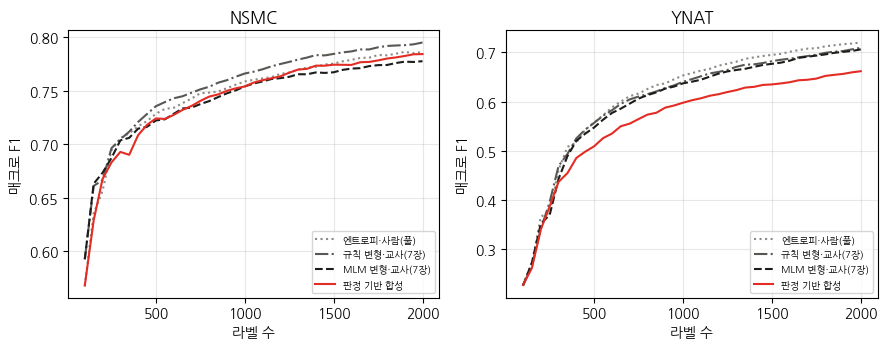

In [21]:
# ── 시나리오별 비교 (표 18.2) ────
def pool_row(name, scen, key, g, oracle):
    a = [alc(x.n_labeled.values, x.f1.values) for _, x in g.groupby("seed")]
    last = g[g.n_labeled == BUDGET]
    tok = last.filter(regex="^tok").sum(1).mean() if g.filter(regex="^tok").shape[1] else 0.0
    return dict(data=name, 시나리오=scen, 구성=key, ALC=np.mean(a), final=last.f1.mean(),
                cost_h=(BUDGET if oracle == "사람" else N_INIT) * UNIT[name], tok=tok)

rows = []
for name in DATA:
    c3 = pd.read_csv(f"results/ch03_{name}.csv")
    rows.append(pool_row(name, "풀", "엔트로피·사람", c3[c3.strategy == "엔트로피"], "사람"))
    c15 = pd.concat([pd.read_csv(f"results/ch15_parts/loop_{name}_r0_{s}.csv") for s in SEEDS])
    rows.append(pool_row(name, "풀", "엔트로피·Jev", c15[["seed", "n_labeled", "f1", "tok"]], "Jev"))
    c17 = pd.concat([pd.read_csv(f"results/ch17_parts/loop_{name}_Jev_불일치-Jev_{s}.csv") for s in SEEDS])
    rows.append(pool_row(name, "풀", "Jev 불일치·Jev", c17[["seed", "n_labeled", "f1", "tok_q", "tok_o"]], "Jev"))
    t = summarize_stream(sres[sres.data == name]).set_index("strategy")
    for arm in S_ARMS:
        rows.append(dict(data=name, 시나리오="스트림", 구성=arm, ALC=t.loc[arm, "ALC_label"], final=t.loc[arm, "final"],
                         cost_h=(t.loc[arm, "labels"] if arm in ("Random", "VU") else N_INIT + REVIEW * t.loc[arm, "reviews"]) * UNIT[name],
                         tok=t.loc[arm, "tok"]))
    c7 = pd.read_csv(f"results/ch07_{name}.csv")
    for key in ("규칙 변형", "MLM 변형"):
        rows.append(pool_row(name, "합성", f"{key}·교사(7장)", c7[c7.strategy == key], "Jev") | dict(cost_h=N_INIT * UNIT[name]))
    rows.append(pool_row(name, "합성", "판정 기반 합성", yres[yres.data == name][["seed", "n_labeled", "f1", "tok"]], "Jev"))
tab2 = pd.DataFrame(rows)
for name in DATA:
    print(f"\n{name} 시나리오별 비교 (cost_h = 사람 비용(원), tok = Jev 입력 토큰)")
    print(tab2[tab2.data == name].drop(columns="data").round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    for key, g, (c, ls) in (("엔트로피·사람(풀)", pd.read_csv(f"results/ch03_{name}.csv").query("strategy == '엔트로피'"), (GRAY2, ":")),
                            ("규칙 변형·교사(7장)", pd.read_csv(f"results/ch07_{name}.csv").query("strategy == '규칙 변형'"), (GRAY, "-.")),
                            ("MLM 변형·교사(7장)", pd.read_csv(f"results/ch07_{name}.csv").query("strategy == 'MLM 변형'"), (INK, "--")),
                            ("판정 기반 합성", yres[yres.data == name], (ACCENT, "-"))):
        m = g.groupby("n_labeled").f1.mean()
        ax.plot(m.index, m.values, color=c, ls=ls, lw=1.5, label=key)
    ax.set(title=name.upper(), xlabel="라벨 수", ylabel="매크로 F1")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("out/ch18_synth.png", dpi=200)

In [22]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
new = sres.groupby(["data", "seed", "strategy"]).new.max().sum() + dres.groupby(["seed", "strategy"]).new.max().sum() \
      + yres.groupby(["data", "seed"]).new.max().sum() + sum(pd.read_csv(f).n_in.sum() for f in glob.glob("results/ch18_parts/latency_*.csv"))
print(f"이번에 새로 쓴 입력 토큰: {new:,.0f}")

이번에 새로 쓴 입력 토큰: 25,365,997
